# Pricing the crack spread options
### European exchange options and spread calls under correlated Black dynamics

A refinery buys crude and sells refined products. A delivery disruption can move the price of gasoline and the cost of crude by very different amounts. The margin between them matters even when both prices rise. A call on the margin gives its buyer upside above a threshold. A refiner seeking a floor on its existing margin would instead look at a put.

This notebook studies a **stylised 1:1 gasoline–crude crack** per barrel. We first test a simulation against an exact exchange-option price, then measure the accuracy of a fast approximation for a call with a cash strike. The final appendix explains a separate swing example with multiple exercise dates.

**Run it** : Just use a Python 3.10+ Jupyter kernel with NumPy and Matplotlib. Edit the **Market and experiment settings** cell, then run all cells. Inputs are illustrative. Premiums are USD per reference barrel and exercise is cash-settled at option expiry.

## 1. Contract and units

We write $F_R$ for the gasoline future in USD/barrel and $F_C$ for the crude future in USD/barrel. For gasoline quoted in **USD/gallon**, multiply by 42. Both futures must still be outstanding at option expiry $T$. The two delivery months are fixed when the contract is specified.

For a crude-leg quantity $q>0$ and cash strike $K$, the buyer receives
$$H_T=(F_R(T)-qF_C(T)-K)^+,\qquad x^+=\max(x,0).$$
At $q=1$ this is our 1:1 crack. At $K=0$ it is an **exchange option**. Positive $K$ sets the margin threshold. It can represent a fixed processing-cost estimate when that is appropriate for the contract.

In [1]:
from abc import ABC, abstractmethod
from dataclasses import dataclass, replace
from math import exp, isfinite, log, sqrt
from statistics import NormalDist               # haha we could use scipy.stats.norm but this is in the standard library now

import matplotlib.pyplot as plt
import numpy as np


@dataclass(frozen=True)
class Market:
    """Hold two futures quotes, annualised log volatilities and a flat rate."""

    refined: float
    crude: float
    vol_refined: float
    vol_crude: float
    rho: float
    expiry: float
    rate: float

    def __post_init__(self):
        """Reject invalid model inputs before pricing."""
        if not all(isfinite(x) for x in vars(self).values()):
            raise ValueError("All market inputs must be finite.")
        if min(self.refined, self.crude) <= 0:
            raise ValueError("Black futures prices must be positive.")
        if min(self.vol_refined, self.vol_crude, self.expiry) < 0:
            raise ValueError("Negative volatility or time is invalid.")
        if not -1 <= self.rho <= 1:
            raise ValueError("Correlation must lie between -1 and 1.")

    @property
    def discount(self):
        """Discount one dollar paid at expiry."""
        return exp(-self.rate * self.expiry)


@dataclass(frozen=True)
class SpreadCall:
    """Receive one output unit against an input quantity and cash strike."""

    strike: float = 0.0
    quantity: float = 1.0

    def __post_init__(self):
        """Require finite terms and a positive input quantity."""
        if not isfinite(self.strike):
            raise ValueError("Strike must be finite.")
        if not isfinite(self.quantity) or self.quantity <= 0:
            raise ValueError("Input quantity must be finite and positive.")

    def payoff(self, refined, crude):
        """Return cash flows in the common quote unit."""
        return np.maximum(refined - self.quantity * crude - self.strike, 0)

### Market and experiment settings

Change the futures quotes, volatilities, correlation, contract terms and simulation budget here. The same inputs feed all three implemented engines.

In [2]:
market = Market(
    refined=2.10 * 42, crude=75.0,
    vol_refined=0.32, vol_crude=0.27, rho=0.75,
    expiry=0.5, rate=0.03,  # By default, half a year to expiry.
)
crack = SpreadCall(strike=12.0, quantity=1.0)
exchange = replace(crack, strike=0.0)
n_paths = 200_000  # Use at least 100 paths for the convergence figure.
seed = 42

We use illustrative annualised volatilities of 27% for crude oil and 32% for gasoline, broadly consistent with the 30–40% order of magnitude observed in quieter market conditions; relevant benchmarks include the WTI CVOL (CLVL), RBOB Gasoline CVOL (RBVL) and oil ETF volatility index (OVX), although levels vary substantially with maturity and market conditions.

## 2. Risk-neutral dynamics

For deterministic rates, the futures are martingales under our pricing measure. The model specifies
$$dF_i(t)=\sigma_i F_i(t)\,dW_i(t),\qquad d\langle W_R,W_C\rangle_t=\rho\,dt.$$
For independent standard normals $Z,U$, set $Z_R=Z$ and $Z_C=\rho Z+\sqrt{1-\rho^2}U$. Exact terminal sampling gives
$$F_i(T)=F_i(0)\exp\!\left(-\tfrac12\sigma_i^2T+\sigma_i\sqrt{T}Z_i\right).$$
Only the terminal pair enters these European payoffs. No time grid is needed. Volatilities and correlation are constant over the option life.

We do not need to discount the futures, as they are already forward prices.

In [3]:
def terminal_futures(market, paths, seed):
    """Draw correlated terminal futures exactly under Black dynamics."""
    if paths < 2:
        raise ValueError("At least two paths are required.")
    z, u = np.random.default_rng(seed).standard_normal((2, paths))
    crude_shock = market.rho * z + sqrt(1 - market.rho**2) * u

    def evolve(initial, vol, shock):
        total_vol = vol * sqrt(market.expiry)
        return initial * np.exp(total_vol * shock - 0.5 * total_vol**2)

    return (
        evolve(market.refined, market.vol_refined, z),
        evolve(market.crude, market.vol_crude, crude_shock),
    )

## 3. Three pricing engines

**Margrabe.** With zero strike, exchanging the two legs admits an exact formula. Let $A=F_R(0)$, $B=qF_C(0)$ and $w=\sqrt{T}\sqrt{\sigma_R^2+\sigma_C^2-2\rho\sigma_R\sigma_C}$. Define
$$C(A,B,w)=e^{-rT}[A\Phi(d_1)-B\Phi(d_2)],\qquad d_1=\frac{\log(A/B)}{w}+\frac w2,\quad d_2=d_1-w.$$
Here $\Phi$ is the standard normal CDF. At zero total volatility use discounted intrinsic value.

**Kirk.** For a positive strike, we use $B=qF_C(0)+K$ and freeze the input-leg weight at $\beta=qF_C(0)/B$. We substitute $\beta\sigma_C$ for $\sigma_C$ in $w$ and apply the same function $C$. The translation by $K$ is exact. Freezing the weight is the approximation.

**Monte Carlo.** From independent discounted cash flows $Y_j=e^{-rT}H_T^{(j)}$, estimate $V$ by $\bar Y$ and its standard error by $s_Y/\sqrt N$. The approximate pointwise 95% interval is $\bar Y\pm1.96\,s_Y/\sqrt N$. It measures sampling uncertainty under the chosen model.

In [4]:
@dataclass(frozen=True)
class Quote:
    """Store a premium and optional Monte Carlo standard error."""

    value: float
    se: float = 0.0


class Pricer(ABC):
    """Price a European spread contract using a common interface."""

    @abstractmethod
    def price(self, market, contract):
        """Return a Quote in dollars per reference barrel."""


def exchange_value(market, input_leg, input_vol):
    """Evaluate the exchange formula, including its deterministic limit."""
    output_vol = market.vol_refined
    variance = ((output_vol - input_vol)**2
                + 2 * output_vol * input_vol * (1 - market.rho))
    width = sqrt(market.expiry * variance)
    if width == 0:
        return market.discount * max(market.refined - input_leg, 0)
    d1 = log(market.refined / input_leg) / width + width / 2
    cdf = NormalDist().cdf
    return market.discount * (
        market.refined * cdf(d1) - input_leg * cdf(d1 - width)
    )


class Margrabe(Pricer):
    """Exact benchmark for zero-strike exchange options."""

    def price(self, market, contract):
        """Price a zero-strike contract analytically."""
        if contract.strike != 0:
            raise ValueError("Margrabe requires zero cash strike.")
        leg = contract.quantity * market.crude
        return Quote(exchange_value(market, leg, market.vol_crude))


class Kirk(Pricer):
    """Approximate a spread call using a frozen input-leg weight."""

    def price(self, market, contract):
        """Return the Kirk premium for a positive shifted input leg."""
        crude_leg = contract.quantity * market.crude
        shifted = crude_leg + contract.strike
        if shifted <= 0:
            raise ValueError("Kirk requires a positive shifted input leg.")
        effective_vol = market.vol_crude * crude_leg / shifted
        return Quote(exchange_value(market, shifted, effective_vol))


def estimate(samples):
    """Estimate the mean and standard error of independent observations."""
    return Quote(samples.mean(), samples.std(ddof=1) / sqrt(samples.size))


@dataclass(frozen=True)
class MonteCarlo(Pricer):
    """Use reproducible, independent draws within each price estimate."""

    paths: int
    seed: int

    def cashflows(self, market, contract):
        """Generate one discounted payoff per path."""
        refined, crude = terminal_futures(market, self.paths, self.seed)
        return market.discount * contract.payoff(refined, crude)

    def price(self, market, contract):
        """Return a simulated price and its standard error."""
        return estimate(self.cashflows(market, contract))

## 4. Base-case premiums

Apply the same pricing interface to both contracts. Read the formula-to-simulation difference alongside the standard error.

In [5]:
simulation = MonteCarlo(n_paths, seed)
cases = [("Exchange", exchange, Margrabe()), ("Crack", crack, Kirk())]
print("Contract    Formula     Premium       MC      MC 95% interval")
for label, contract, engine in cases:
    reference = engine.price(market, contract).value
    quote = simulation.price(market, contract)
    margin = 1.96 * quote.se
    print(f"{label:10}  {type(engine).__name__:8}  {reference:7.4f}  "
          f"{quote.value:7.4f}   "
          f"[{quote.value-margin:.4f}, {quote.value+margin:.4f}]")

Contract    Formula     Premium       MC      MC 95% interval
Exchange    Margrabe  13.8792  13.8815   [13.8287, 13.9344]
Crack       Kirk       5.7633   5.7798   [5.7405, 5.8191]


**Reading the result.** With the default futures quotes, the current gasoline–crude margin (initial margin) is $88.20-75.00=13.20$ USD/barrel. At a strike of 12 USD/barrel, the call therefore has an intrinsic value of $\max(13.20-12,0)=1.20$ USD/barrel. This is the payoff we would obtain if the option expired today — not its current premium. The premium reflects the discounted expected payoff **at expiry**, including the possibility of a wider margin, while the holder’s payoff remains floored at zero if the margin falls below the strike.

For the **zero-strike exchange call**, Margrabe gives the exact price under our model assumptions, providing a benchmark for the Monte Carlo estimate. For the **positive-strike crack call**, Kirk provides an approximation. We interpret its difference from Monte Carlo alongside the reported confidence interval: if Kirk lies inside that interval, the simulation cannot distinguish its approximation error from sampling noise at the stated confidence level. This does not establish that Kirk is exact; increasing the simulation budget may reveal a small but persistent discrepancy.

## 5. How quickly does Monte Carlo converge?

We plot here the estimated premiums for increasing prefixes of a single sample. The horizontal lines use Margrabe on the left and Kirk on the right. The shaded areas show pointwise 95% intervals.

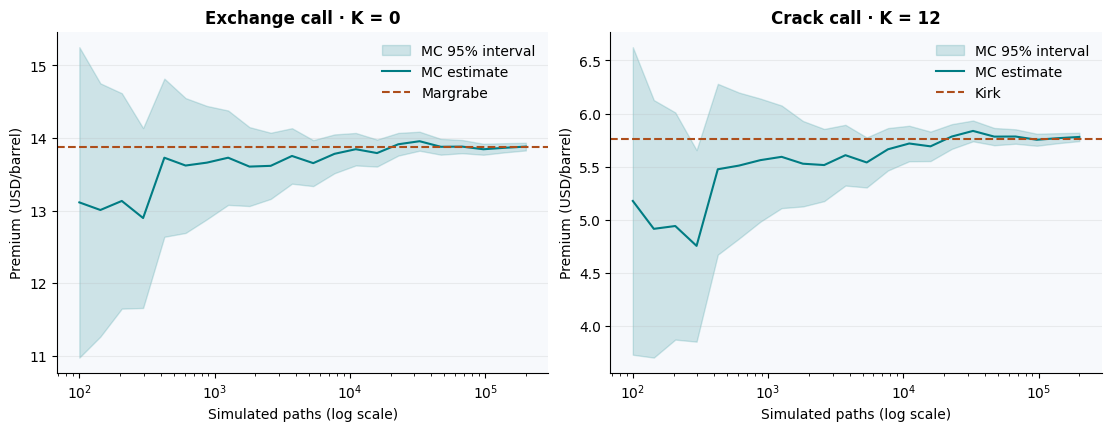

In [6]:
if n_paths < 100:
    raise ValueError("Use at least 100 paths for the convergence experiment.")

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "font.size": 10,
    "figure.facecolor": "white", "axes.facecolor": "#f7f9fc",
})
teal, orange = "#007c83", "#ad4e1b"
sizes = np.unique(np.geomspace(100, n_paths, 22).astype(int))
sizes[-1] = n_paths
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
for ax, (label, contract, engine) in zip(axes, cases):
    flows = simulation.cashflows(market, contract)
    stats = [estimate(flows[:n]) for n in sizes]
    means = np.array([q.value for q in stats])
    bands = 1.96 * np.array([q.se for q in stats])
    ax.fill_between(sizes, means-bands, means+bands, color=teal,
                    alpha=0.17, label="MC 95% interval")
    ax.plot(sizes, means, color=teal, label="MC estimate")
    ax.axhline(engine.price(market, contract).value, color=orange,
               linestyle="--", label=type(engine).__name__)
    ax.set(xscale="log", title=f"{label} call · K = {contract.strike:g}",
           xlabel="Simulated paths (log scale)", ylabel="Premium (USD/barrel)")
    ax.grid(axis="y", alpha=0.2)
    ax.legend(frameon=False)
plt.show()

**Reading the curves.** We plot the estimated premiums against the number of simulated paths, using a logarithmic horizontal axis to show both small and large simulation budgets clearly. Equal horizontal distances represent equal multiplicative increases in sample size. The shaded regions show pointwise 95% confidence intervals, which narrow as sampling uncertainty decreases.

The standard error decreases approximately as \(1/\sqrt{N}\): quadrupling the sample size roughly halves it, while increasing it from 100 to 100,000 paths reduces it by a factor of about 31.6. Individual estimates need not approach their reference monotonically and can cross it as paths are added.

For the exchange call, **Margrabe** provides the exact model price, so discrepancies reflect Monte Carlo sampling error. For the crack call, **Kirk** is an approximation: a persistent gap can reflect approximation error even as Monte Carlo uncertainty shrinks. Successive plotted estimates share simulated paths and are therefore correlated; the pointwise 95% intervals do not provide simultaneous 95% coverage over the entire figure.

## 6. Where does Kirk depart from simulation?

Sweep the cash strike while reusing the same terminal futures across strikes. Show the price levels and, on a separate scale, the difference between Kirk and the Monte Carlo estimate.

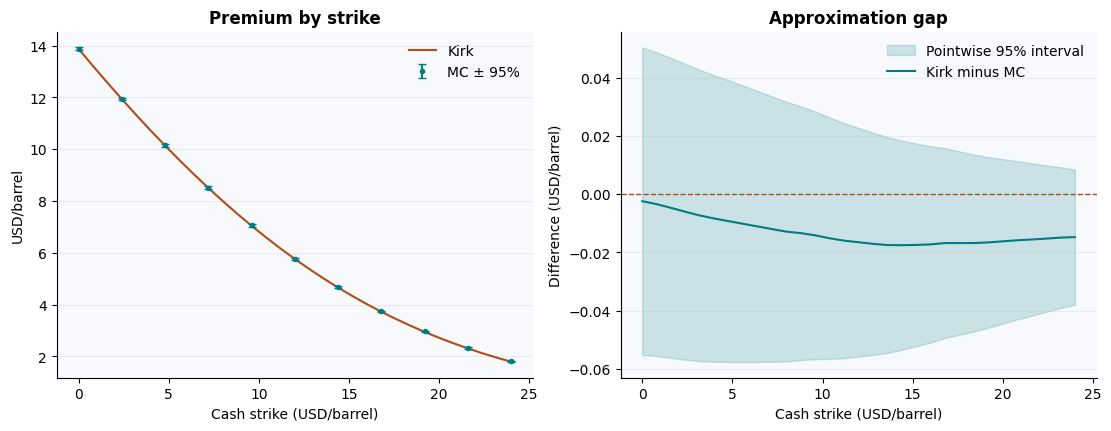

In [7]:
refined, crude = terminal_futures(market, n_paths, seed)
spread = refined - crack.quantity * crude
strikes = np.linspace(0, max(2 * crack.strike, 0.3 * market.crude), 31)
model_prices, mc_prices, half_widths = [], [], []
for strike in strikes:
    contract = replace(crack, strike=strike)
    quote = estimate(market.discount * np.maximum(spread - strike, 0))
    mc_prices.append(quote.value)
    half_widths.append(1.96 * quote.se)
    model_prices.append(Kirk().price(market, contract).value)

mc_prices, half_widths = np.array(mc_prices), np.array(half_widths)
gap = np.array(model_prices) - mc_prices
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2),
                                  constrained_layout=True)
left.plot(strikes, model_prices, color=orange, label="Kirk")
left.errorbar(strikes[::3], mc_prices[::3], yerr=half_widths[::3],
              fmt="o", ms=3, color=teal, capsize=3, label="MC ± 95%")
right.fill_between(strikes, gap-half_widths, gap+half_widths,
                   color=teal, alpha=0.18, label="Pointwise 95% interval")
right.plot(strikes, gap, color=teal, label="Kirk minus MC")
right.axhline(0, color=orange, linestyle="--", linewidth=1)
for ax, title, ylabel in (
    (left, "Premium by strike", "USD/barrel"),
    (right, "Approximation gap", "Difference (USD/barrel)"),
):
    ax.set(title=title, xlabel="Cash strike (USD/barrel)", ylabel=ylabel)
    ax.grid(axis="y", alpha=0.2)
    ax.legend(frameon=False)
plt.show()

**Reading the strike sweep.** We vary the strike while keeping all other inputs fixed. A higher strike lowers—or leaves unchanged—the payoff on each simulated path, which in turn lowers the option premium. On the right, we plot **Kirk minus Monte Carlo**: a negative value means Kirk prices below the Monte Carlo estimate, while a positive value means it prices above it. The shaded band reflects Monte Carlo sampling uncertainty. If it crosses zero, we cannot confidently determine whether Kirk overprices or underprices the model’s true value with this simulation budget. A band entirely above zero indicates overpricing by Kirk; a band entirely below zero indicates underpricing, at the stated confidence level. These are pointwise conclusions, and estimates across strikes are correlated because we reuse the same simulated draws.

## 7. Implementation checks

Test model identities and degenerate cases independently of the editable scenario. The stochastic check uses a fixed seed and a five-standard-error tolerance.

In [8]:
test_market = Market(88.2, 75, 0.32, 0.27, 0.75, 0.5, 0.03)
test_call = SpreadCall()
benchmark = Margrabe().price(test_market, test_call).value
assert np.isclose(Kirk().price(test_market, test_call).value, benchmark)
mc_check = MonteCarlo(100_000, 7).price(test_market, test_call)
assert abs(mc_check.value - benchmark) < 5 * mc_check.se
for engine in (Kirk(), Margrabe(), MonteCarlo(1000, 0)):
    instant = engine.price(replace(test_market, expiry=0), test_call)
    assert np.isclose(instant.value, 13.2)
scaled_call = SpreadCall(quantity=1.2)
scaled_market = replace(test_market, crude=1.2 * test_market.crude)
assert np.isclose(Margrabe().price(test_market, scaled_call).value,
                  Margrabe().price(scaled_market, test_call).value)
print("Passed: zero-strike identity, MC benchmark, expiry and leg scaling.")

Passed: zero-strike identity, MC benchmark, expiry and leg scaling.


**What the checks establish.** The zero-strike engines agree, the simulation hits its analytic benchmark within the chosen tolerance, and the payoff scales the crude leg consistently. Calibration to market quotes is a separate exercise.

## Appendix · Swing on one crude future

Swing contracts provide flexibility over when — and, depending on their terms, how much — to buy or sell a commodity. They are particularly associated with gas supply, where demand varies with weather and operational needs. Unlike a standard Bermudan option, which allows a single exercise on a predefined calendar, a swing can allow multiple exercises subject to contractual limits.

For comparison with our two European contracts, we consider a simplified **cash-settled swing on a single crude-oil future**. We have six equally spaced exercise dates and up to three optional rights, with at most one one-barrel unit exercised per date. The underlying is the crude future itself — not gasoline and not the crack spread. Unused rights expire without penalty.

Each exercise immediately pays
$$
h(F_t)=(F_t-K)^+,
$$
where $F_t$ is the price of the same crude future observed at time $t$, and $K$ is the contractual exercise price, both in USD/barrel. Exercising generates a cash payment: it neither delivers physical oil nor transfers a futures position to the holder.

**Two calendars, two roles.** The swing specifies when we may exercise; the underlying future has its own expiration and delivery terms. Monthly futures expiries do not imply a minimum one-month holding period: an existing contract can be traded close to expiration. In our setup, the underlying future must remain outstanding through the swing’s final exercise date. We do not model a strip of different delivery months or a physical supply contract with daily deliveries and volume obligations.

**The economic decision.** With three rights across six dates, an attractive payoff today must be weighed against the value of preserving a right for a potentially better opportunity later. At an exercise node with $j>0$ rights remaining, we therefore use
$$
V_j=\max\left\{C_j,\;h(F)+C_{j-1}\right\},
$$
where $V_j$ is the value before the exercise decision and $C_j$ is the discounted expected value at the next tree step with $j$ rights remaining. Waiting preserves all $j$ rights; exercising earns $h(F)$ immediately and leaves $j-1$ rights alive.

Between contractual exercise dates, no decision is available, so $V_j=C_j$. With no rights remaining, $V_0=0$; at the final exercise date, $V_j=h(F)$ for every $j>0$, since only one unit can be exercised then.

The tree’s transition probability is chosen to make the futures price a martingale under the risk-neutral measure; it is not an arbitrary forecast of upward price movements. This example isolates the value of multiple exercise opportunities and provides a transparent numerical benchmark, rather than representing a fully specified physical oil-supply contract.

In [9]:
def swing_tree(market, strike, rights, dates, substeps):
    """Value a multiple-exercise call on one future by backward induction."""
    if dates < 1 or substeps < 1 or rights < 0 or market.expiry <= 0:
        raise ValueError("Use a positive horizon and grid, and nonnegative rights.")
    rights = min(rights, dates)
    if market.vol_crude == 0:
        times = market.expiry * np.arange(1, dates + 1) / dates
        factors = sorted(np.exp(-market.rate * times), reverse=True)
        return max(market.crude - strike, 0) * sum(factors[:rights])

    steps = dates * substeps
    dt = market.expiry / steps
    log_up = market.vol_crude * sqrt(dt)
    prob_up = 1 / (1 + exp(log_up))
    discount = exp(-market.rate * dt)

    def intrinsic(i):
        nodes = market.crude * np.exp((2 * np.arange(i + 1) - i) * log_up)
        return np.maximum(nodes - strike, 0)

    values = np.zeros((rights + 1, steps + 1))
    values[1:] = intrinsic(steps)
    for i in reversed(range(steps)):
        wait = discount * (
            (1 - prob_up) * values[:, :-1] + prob_up * values[:, 1:]
        )
        values = wait.copy()
        if i > 0 and i % substeps == 0:
            values[1:] = np.maximum(wait[1:], intrinsic(i) + wait[:-1])
    return values[rights, 0]


swing_strike, rights, dates, substeps = 75, 3, 6, 20
if market.expiry > 0:
    for grid in (substeps, 2 * substeps):
        premium = swing_tree(market, swing_strike, rights, dates, grid)
        print(f"{grid:2} steps per interval | Swing premium: {premium:.4f} USD")
else:
    print("Choose a positive horizon for the swing exercise grid.")

20 steps per interval | Swing premium: 15.3506 USD
40 steps per interval | Swing premium: 15.3696 USD


**Reading the tree.** With the default inputs, doubling the grid changes the premium by about two cents. That difference reflects discretisation of the futures dynamics. The contractual exercise dates remain the same.

## Closing notes

We first use Margrabe’s exact zero-strike formula to validate our Monte Carlo implementation under the assumed dynamics. We then extend the comparison to positive strikes, using the strike sweep to assess whether Kirk’s approximation is sufficiently accurate for a chosen pricing tolerance. Monte Carlo confidence intervals help distinguish approximation error from sampling noise: increasing the simulation budget improves precision, but does not correct the assumptions of the underlying model.

The premiums depend on both volatilities and their correlation. As a further experiment, we could lower the correlation while keeping all other inputs fixed and examine the resulting increase in the exchange option premium. The exchange option’s effective variance,
$$
\sigma_{\mathrm{eff}}^2
=\sigma_R^2+\sigma_C^2-2\rho\sigma_R\sigma_C,
$$
would then increases, raising its premium: less synchronised price movements create more opportunities for gasoline to outperform crude, while the option limits the holder’s payoff to zero when the exchange is unfavourable.

This experiment connects numerical pricing with economic intuition. Agreement between methods establishes consistency within our model; applying it to market decisions would additionally require suitable volatility and correlation calibration, consistent contract specifications and an assessment of model limitations.

**References**

- U.S. EIA, [An introduction to crack spreads](https://www.eia.gov/todayinenergy/detail.php?id=1630).
- Carmona & Durrleman, [Pricing and hedging spread options](https://carmona.princeton.edu/document/306).
- Lo, [A simple derivation of Kirk’s approximation for spread options](https://www.sciencedirect.com/science/article/pii/S0893965913001171).
- Carmona & Touzi, [Optimal multiple stopping and valuation of swing options](https://doi.org/10.1111/j.1467-9965.2007.00331.x).